# ECG Beat Classifier v2: ConvNeXt-Atto on MIT-BIH (5 classes), long training run
Drop-in replacement for the first model. **Same input, same output, same file names, same `ecg_inference.py`.**
Upload the new `ecg_convnext_atto.pth` over the old one on Hugging Face and nothing else changes.

**Setup before running:** Add dataset `shayanfazeli/heartbeat` | Accelerator: **GPU T4 x2** | Internet: **ON** (pretrained weights).

**Why the first model stopped at ~95.7% / macro-F1 0.82:** it was planned for 30 epochs but cut at epoch 7 by the time cap, so the learning-rate schedule never came down (it was still at a high LR). v2 measures the real speed first and sizes the schedule to the full time budget, so the LR anneals to ~0 at the end.

**What changed inside (the interface did not):**
| Change | Why |
|---|---|
| Epoch count and cosine LR sized to a **110 min** budget | model actually converges |
| EMA of weights (used for validation and for the saved model) | smoother, more accurate final weights |
| Stronger per-sample augmentation (time shift, stretch, amplitude, baseline wander, noise) | better generalisation, mainly for S and F |
| Gentler rare-class oversampling (`sampler_power` 0.6) | the old model over-predicted F (precision 0.40) |
| Val-tuned class bias folded into the final layer's bias, then temperature scaling | fixes the precision/recall balance of S and F with **no change to the inference code** |
| Checkpoint every epoch, resume if the session drops | a 2 hour run is not lost |

**Selection metric:** mean of validation balanced accuracy and macro-F1. The official `mitbih_test.csv` is only touched at the very end.

## 1. Setup and config

In [3]:
import os, time, json, glob, random, subprocess, sys, copy, math
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, roc_curve, auc, balanced_accuracy_score)
from sklearn.preprocessing import label_binarize

try:
    import timm
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "timm"])
    import timm

SEED = 42
def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(SEED)

CFG = dict(
    model_name="convnext_atto",   # unchanged
    img_size=224,                 # unchanged
    batch_size=256,
    max_lr=8e-4, min_lr=1e-6, warmup_frac=0.04,
    weight_decay=0.05,
    samples_per_epoch=30000,
    sampler_power=0.6,            # 0 = natural distribution, 1 = fully balanced
    label_smoothing=0.05,
    drop_rate=0.1,
    drop_path_rate=0.1,
    ema_decay=0.999,
    time_budget_min=110,          # training + per-epoch validation; the epoch count is derived from this
    min_epochs=8, max_epochs=60,
    val_fraction=0.12,
    ckpt="/kaggle/working/ckpt_last.pt",
)
CLASSES = ["N (Normal)", "S (Supraventricular)", "V (Ventricular)", "F (Fusion)", "Q (Unknown)"]
SHORT = ["N", "S", "V", "F", "Q"]
NUM_CLASSES = len(CLASSES)
SPEC_CFG = [(32, 1), (64, 2), (128, 4)]       # (n_fft, hop) per channel - MUST match ecg_inference.py

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
if not use_amp:
    print("WARNING: no GPU found. Settings > Accelerator > GPU T4 x2")
n_gpu = torch.cuda.device_count()
print("device:", device, "| GPUs:", n_gpu, [torch.cuda.get_device_name(i) for i in range(n_gpu)])
os.makedirs("/kaggle/working", exist_ok=True)

device: cuda | GPUs: 2 ['Tesla T4', 'Tesla T4']


## 2. Load data and split
The official `mitbih_test.csv` is the final **test** set. Validation is carved out of the training file (stratified).

In [4]:
def find(name):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    assert hits, f"{name} not found. Add the 'heartbeat' dataset (shayanfazeli) to this notebook."
    return hits[0]

train_df = pd.read_csv(find("mitbih_train.csv"), header=None)
test_df  = pd.read_csv(find("mitbih_test.csv"),  header=None)

X_all  = train_df.iloc[:, :187].values.astype(np.float32)
y_all  = train_df.iloc[:, 187].values.astype(np.int64)
X_test = test_df.iloc[:, :187].values.astype(np.float32)
y_test = test_df.iloc[:, 187].values.astype(np.int64)

X_tr, X_val, y_tr, y_val = train_test_split(
    X_all, y_all, test_size=CFG["val_fraction"], stratify=y_all, random_state=SEED)

print(pd.DataFrame({"class": CLASSES,
                    "train": np.bincount(y_tr, minlength=NUM_CLASSES),
                    "val":   np.bincount(y_val, minlength=NUM_CLASSES),
                    "test":  np.bincount(y_test, minlength=NUM_CLASSES)}).to_string(index=False))

to_g = lambda a, dt: torch.tensor(a, dtype=dt, device=device)     # dataset is tiny: keep it all on the GPU
Xtr_g, ytr_g = to_g(X_tr, torch.float32), to_g(y_tr, torch.long)
Xval_g, yval_g = to_g(X_val, torch.float32), to_g(y_val, torch.long)
Xte_g, yte_g = to_g(X_test, torch.float32), to_g(y_test, torch.long)

               class  train  val  test
          N (Normal)  63774 8697 18118
S (Supraventricular)   1956  267   556
     V (Ventricular)   5094  694  1448
          F (Fusion)    564   77   162
         Q (Unknown)   5659  772  1608


## 3. Beat -> image (GPU) and augmentation
The beat-to-image conversion is **identical** to v1 and to `ecg_inference.py`. Only the training-time augmentation is stronger (per sample, not per batch).

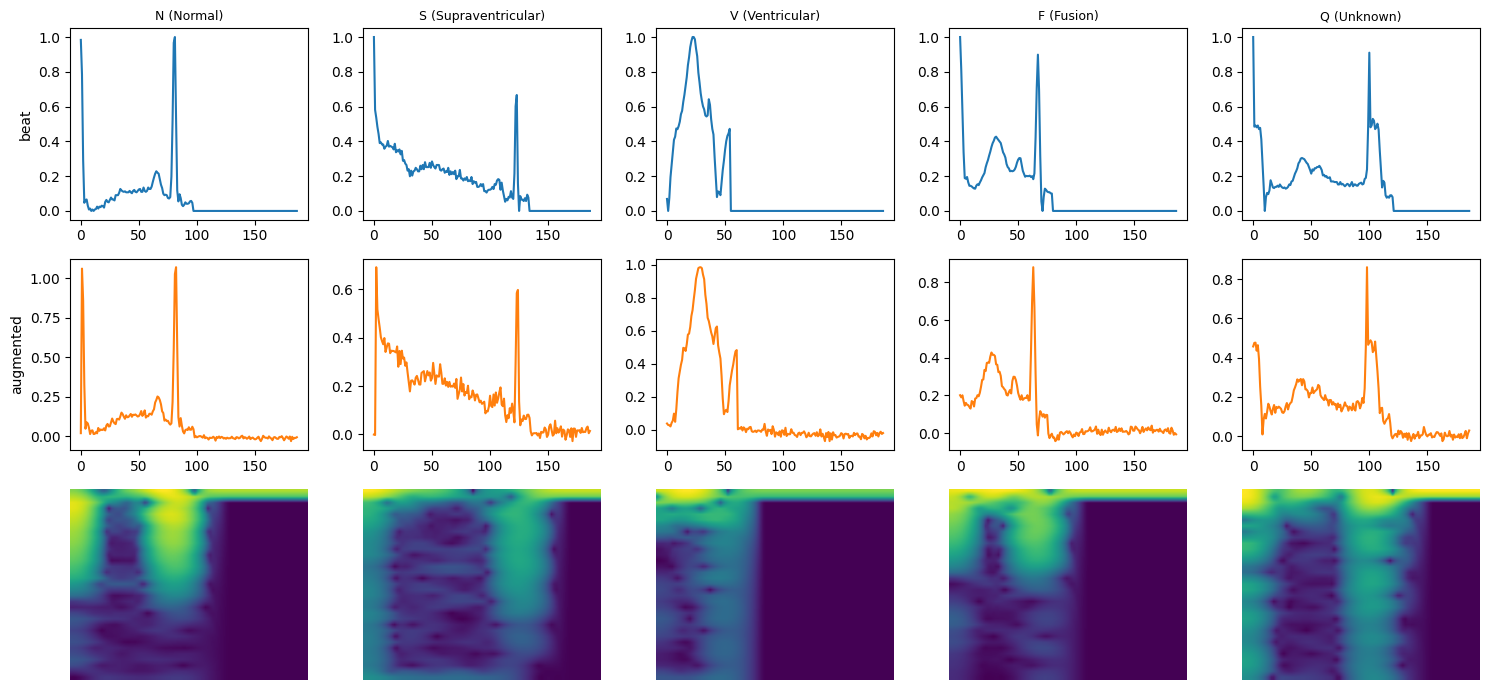

In [5]:
_win = {}
def _window(n):
    if n not in _win:
        _win[n] = torch.hann_window(n, device=device)
    return _win[n]

@torch.no_grad()
def to_image(x, size=CFG["img_size"]):
    # x: (B, 187) -> (B, 3, size, size). Same maths as ecg_inference.py._to_image
    with torch.autocast(device.type, enabled=False):
        x = x.float()
        x = x - x.mean(dim=1, keepdim=True)
        chans = []
        for n_fft, hop in SPEC_CFG:
            S = torch.stft(x, n_fft=n_fft, hop_length=hop, win_length=n_fft,
                           window=_window(n_fft), center=True, return_complex=True).abs()
            S = torch.log1p(20.0 * S).unsqueeze(1)
            chans.append(F.interpolate(S, size=(size, size), mode="bilinear", align_corners=False))
        img = torch.cat(chans, 1)
        m = img.mean(dim=(2, 3), keepdim=True)
        s = img.std(dim=(2, 3), keepdim=True) + 1e-5
        return (img - m) / s

@torch.no_grad()
def augment(x):
    # per-sample, physiologically plausible, training only
    B, L = x.shape
    dev = x.device
    r = lambda lo, hi: lo + (hi - lo) * torch.rand(B, 1, device=dev)
    ar = torch.arange(L, device=dev, dtype=torch.float32)[None]
    # time stretch (50% of beats, +-8%) about the beat centre + time shift (+-6 samples), zero fill outside
    s = torch.where(torch.rand(B, 1, device=dev) < 0.5, r(0.92, 1.08), torch.ones(B, 1, device=dev))
    sh = torch.randint(-6, 7, (B, 1), device=dev).float()
    pos = (ar - 93.0) * s + 93.0 + sh
    inside = ((pos >= 0) & (pos <= L - 1)).float()
    pos = pos.clamp(0, L - 1)
    i0 = pos.floor().long(); i1 = (i0 + 1).clamp(max=L - 1); w = pos - i0.float()
    y = (x.gather(1, i0) * (1 - w) + x.gather(1, i1) * w) * inside
    y = y * r(0.85, 1.15)                                                  # amplitude +-15%
    y = y + r(0, 0.04) * torch.sin(2 * math.pi * r(0.3, 1.5) * ar / L + r(0, 2 * math.pi))   # baseline wander
    y = y + r(0, 0.02) * torch.randn_like(y)                               # sensor noise
    return y

fig, ax = plt.subplots(3, NUM_CLASSES, figsize=(3 * NUM_CLASSES, 7))
for c in range(NUM_CLASSES):
    i = int((ytr_g == c).nonzero()[0])
    ax[0, c].plot(Xtr_g[i].cpu().numpy()); ax[0, c].set_title(CLASSES[c], fontsize=9)
    ax[1, c].plot(augment(Xtr_g[i:i+1])[0].cpu().numpy(), c="tab:orange")
    ax[2, c].imshow(to_image(Xtr_g[i:i+1])[0, 1].cpu().numpy(), aspect="auto"); ax[2, c].axis("off")
ax[0, 0].set_ylabel("beat"); ax[1, 0].set_ylabel("augmented")
plt.tight_layout(); plt.show()

## 4. Model
ImageNet-pretrained ConvNeXt-Atto, 5-class head (same architecture and weights layout as v1), plus an EMA copy of the weights.

In [6]:
base_model = timm.create_model(
    CFG["model_name"], pretrained=True, num_classes=NUM_CLASSES,
    drop_rate=CFG["drop_rate"], drop_path_rate=CFG["drop_path_rate"],
).to(device).to(memory_format=torch.channels_last)
model = nn.DataParallel(base_model) if n_gpu > 1 else base_model

ema = copy.deepcopy(base_model).eval()
for p in ema.parameters():
    p.requires_grad_(False)

@torch.no_grad()
def ema_update(step):
    d = min(CFG["ema_decay"], (1 + step) / (10 + step))      # fast warm-up of the average
    ep, mp = list(ema.parameters()), list(base_model.parameters())
    torch._foreach_mul_(ep, d); torch._foreach_add_(ep, mp, alpha=1 - d)
    for be, bm in zip(ema.buffers(), base_model.buffers()):
        be.copy_(bm)

print(f"params: {sum(p.numel() for p in base_model.parameters())/1e6:.2f}M | GPUs used: {max(n_gpu,1)}")

model.safetensors: reconstructing file:   0%|          |  0.00B / 14.8MB            

model.safetensors: downloading bytes:           |  0.00B            

params: 3.38M | GPUs used: 2


## 5. Training
First a short speed test measures the real step time on this GPU, then the number of epochs is chosen so training + validation fits `time_budget_min`. A cosine LR schedule runs over exactly that many steps. A checkpoint is saved every epoch; if the session drops, re-run the notebook and this cell resumes.

In [7]:
from tqdm.auto import tqdm

counts = np.bincount(y_tr, minlength=NUM_CLASSES)
w_class = 1.0 / counts.astype(np.float64) ** CFG["sampler_power"]
w_sample = torch.tensor(w_class[y_tr], dtype=torch.float32, device=device)

criterion = nn.CrossEntropyLoss(label_smoothing=CFG["label_smoothing"])
BS = CFG["batch_size"]
steps_per_epoch = CFG["samples_per_epoch"] // BS
opt = torch.optim.AdamW(model.parameters(), lr=CFG["max_lr"], weight_decay=CFG["weight_decay"])
scaler = torch.amp.GradScaler(device.type, enabled=use_amp)
amp_ctx = lambda: torch.autocast(device.type, dtype=torch.float16, enabled=use_amp)
sync = lambda: torch.cuda.synchronize() if use_amp else None

@torch.no_grad()
def predict_logits(net, X, bs=1024, amp=True):
    net.eval(); out = []
    for i in range(0, len(X), bs):
        img = to_image(X[i:i + bs]).contiguous(memory_format=torch.channels_last)
        with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp and amp):
            out.append(net(img).float())
    return torch.cat(out)

def metrics(y, p):
    return dict(acc=accuracy_score(y, p), bal=balanced_accuracy_score(y, p), f1=f1_score(y, p, average="macro"))
score_of = lambda m: 0.5 * (m["bal"] + m["f1"])          # selection metric

hist = {k: [] for k in ["train_loss", "train_acc_clean", "val_acc", "val_bal", "val_f1", "val_f1_S", "val_f1_F", "lr"]}
clean_idx = torch.randperm(len(Xtr_g), device=device)[:10000]
best_score, best_state, best_epoch, elapsed, start_epoch, gstep = -1.0, None, 0, 0.0, 0, 0
EPOCHS = None

if os.path.exists(CFG["ckpt"]):                                  # ---- resume ----
    ck = torch.load(CFG["ckpt"], map_location="cpu", weights_only=False)
    base_model.load_state_dict(ck["model"]); ema.load_state_dict(ck["ema"])
    opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
    hist, best_score, best_state, best_epoch = ck["hist"], ck["best_score"], ck["best_state"], ck["best_epoch"]
    elapsed, start_epoch, gstep, EPOCHS = ck["elapsed"], ck["epoch"], ck["gstep"], ck["epochs"]
    print(f"[resume] from epoch {start_epoch}/{EPOCHS}, {elapsed/60:.1f} min already used")
else:                                                            # ---- measure speed, plan the run ----
    print("[speed test] 4 forward/backward steps (the first is slow, this is normal)...")
    model.train(); ts = []
    for k in range(4):
        t = time.time()
        b = torch.multinomial(w_sample, BS, replacement=True)
        img = to_image(augment(Xtr_g[b])).contiguous(memory_format=torch.channels_last)
        with amp_ctx():
            loss = criterion(model(img).float(), ytr_g[b])
        opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); sync()
        ts.append(time.time() - t); print(f"   step {k+1}: {ts[-1]:.2f}s")
    opt.zero_grad(set_to_none=True)
    step_t = float(np.median(ts[1:]))
    t = time.time(); predict_logits(ema, Xval_g); predict_logits(ema, Xtr_g[clean_idx]); sync()
    eval_t = time.time() - t
    epoch_t = steps_per_epoch * step_t * 1.03 + eval_t
    EPOCHS = int(np.clip(CFG["time_budget_min"] * 60 // epoch_t, CFG["min_epochs"], CFG["max_epochs"]))
    print(f"[plan] ~{epoch_t:.0f}s per epoch (train {steps_per_epoch*step_t:.0f}s + eval {eval_t:.0f}s) "
          f"-> {EPOCHS} epochs = ~{EPOCHS*epoch_t/60:.0f} min\n")

total_steps = EPOCHS * steps_per_epoch
def lr_at(step):
    w = max(1, int(CFG["warmup_frac"] * total_steps))
    if step < w:
        return CFG["max_lr"] * (step + 1) / w
    p = (step - w) / max(1, total_steps - w)
    return CFG["min_lr"] + (CFG["max_lr"] - CFG["min_lr"]) * 0.5 * (1 + math.cos(math.pi * p))

budget_s = CFG["time_budget_min"] * 60
for epoch in range(start_epoch + 1, EPOCHS + 1):
    t_ep = time.time()
    model.train()
    idx = torch.multinomial(w_sample, steps_per_epoch * BS, replacement=True)
    run = torch.zeros((), device=device)
    bar = tqdm(range(steps_per_epoch), desc=f"Epoch {epoch:02d}/{EPOCHS}", leave=False)
    for s in bar:
        b = idx[s * BS:(s + 1) * BS]
        lr = lr_at(gstep)
        for g in opt.param_groups:
            g["lr"] = lr
        img = to_image(augment(Xtr_g[b])).contiguous(memory_format=torch.channels_last)
        with amp_ctx():
            loss = criterion(model(img).float(), ytr_g[b])
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update()
        ema_update(gstep); gstep += 1
        run += loss.detach()
        if s % 10 == 0:
            bar.set_postfix(loss=f"{loss.item():.3f}", lr=f"{lr:.1e}")

    vp = predict_logits(ema, Xval_g).argmax(1).cpu().numpy()          # validate the EMA weights
    m = metrics(y_val, vp)
    f1c = f1_score(y_val, vp, average=None, labels=range(NUM_CLASSES))
    tr_acc = (predict_logits(ema, Xtr_g[clean_idx]).argmax(1) == ytr_g[clean_idx]).float().mean().item()
    for k, v in zip(hist, [run.item() / steps_per_epoch, tr_acc, m["acc"], m["bal"], m["f1"], f1c[1], f1c[3], lr]):
        hist[k].append(v)

    sc = score_of(m)
    star = ""
    if sc > best_score:
        best_score, best_epoch, star = sc, epoch, "  <- BEST"
        best_state = {k: v.detach().cpu().clone() for k, v in ema.state_dict().items()}
    elapsed += time.time() - t_ep
    torch.save(dict(model=base_model.state_dict(), ema=ema.state_dict(), opt=opt.state_dict(), scaler=scaler.state_dict(),
                    hist=hist, best_score=best_score, best_state=best_state, best_epoch=best_epoch,
                    elapsed=elapsed, epoch=epoch, gstep=gstep, epochs=EPOCHS), CFG["ckpt"])
    print(f"ep {epoch:02d}/{EPOCHS} | loss {hist['train_loss'][-1]:.3f} | train {tr_acc:.4f} | val acc {m['acc']:.4f} "
          f"bal {m['bal']:.4f} F1 {m['f1']:.4f} (S {f1c[1]:.3f} F {f1c[3]:.3f}) | lr {lr:.1e} | "
          f"{elapsed/60:.1f} min used{star}")
    if elapsed > budget_s * 1.10:
        print("[stop] hard time limit reached."); break

ema.load_state_dict(best_state)
print(f"\n[done] restored best EMA weights from epoch {best_epoch} (val score {best_score:.4f}). Total {elapsed/60:.1f} min")

[speed test] 4 forward/backward steps (the first is slow, this is normal)...
   step 1: 10.53s
   step 2: 0.28s
   step 3: 0.19s
   step 4: 0.19s
[plan] ~34s per epoch (train 22s + eval 11s) -> 60 epochs = ~34 min



Epoch 01/60:   0%|          | 0/117 [00:00<?, ?it/s]

ep 01/60 | loss 0.923 | train 0.9082 | val acc 0.9146 bal 0.8322 F1 0.7057 (S 0.566 F 0.254) | lr 3.3e-04 | 0.6 min used  <- BEST


Epoch 02/60:   0%|          | 0/117 [00:00<?, ?it/s]

ep 02/60 | loss 0.569 | train 0.9361 | val acc 0.9393 bal 0.8710 F1 0.7605 (S 0.697 F 0.321) | lr 6.7e-04 | 1.2 min used  <- BEST


Epoch 03/60:   0%|          | 0/117 [00:00<?, ?it/s]

... (111 outputs left out)

Epoch 59/60:   0%|          | 0/117 [00:00<?, ?it/s]

ep 59/60 | loss 0.240 | train 0.9975 | val acc 0.9878 bal 0.9377 F1 0.9280 (S 0.886 F 0.800) | lr 1.6e-06 | 37.4 min used


Epoch 60/60:   0%|          | 0/117 [00:00<?, ?it/s]

ep 60/60 | loss 0.240 | train 0.9975 | val acc 0.9876 bal 0.9366 F1 0.9264 (S 0.884 F 0.795) | lr 1.0e-06 | 38.1 min used

[done] restored best EMA weights from epoch 44 (val score 0.9354). Total 38.1 min


## 6. Fix the precision/recall balance (validation only), then calibrate
Rare-class oversampling shifts the model towards predicting S/F too often or too rarely. A small per-class bias, tuned on the **validation** set to maximise the selection metric, corrects that. It is added to the final layer's bias, so the saved `.pth` keeps the exact same format and `ecg_inference.py` needs no change. Then temperature scaling is fitted on validation, as in v1.

In [8]:
final = copy.deepcopy(ema).eval()
head = final.get_classifier()
assert isinstance(head, nn.Linear) and head.out_features == NUM_CLASSES

val_logits0 = predict_logits(final, Xval_g, amp=False).cpu()
val_sc = lambda bias: score_of(metrics(y_val, (val_logits0 + bias).argmax(1).numpy()))

bias = torch.zeros(NUM_CLASSES)
sc0 = val_sc(bias)
grid = np.round(np.arange(-2.0, 2.01, 0.1), 2)
for _ in range(3):                                   # coordinate ascent, class 0 (N) is the reference
    for c in range(1, NUM_CLASSES):
        best = (val_sc(bias), bias[c].item())
        for g in grid:
            b2 = bias.clone(); b2[c] = float(g)
            s = val_sc(b2)
            if s > best[0] + 1e-6:
                best = (s, float(g))
        bias[c] = best[1]
sc1 = val_sc(bias)
print(f"val score {sc0:.4f} -> {sc1:.4f} with bias {np.round(bias.numpy(), 2)}")
if sc1 - sc0 < 0.002:                                # not worth the risk of fitting noise
    bias.zero_(); print("gain too small, bias not applied")
with torch.no_grad():
    head.bias.add_(bias.to(device))

val_logits = predict_logits(final, Xval_g, amp=False)
T = torch.ones(1, device=device, requires_grad=True)
lbfgs = torch.optim.LBFGS([T], lr=0.1, max_iter=100)
def _closure():
    lbfgs.zero_grad()
    l = F.cross_entropy(val_logits / T.clamp(min=0.05), yval_g)
    l.backward(); return l
lbfgs.step(_closure)
TEMP = float(T.clamp(min=0.05).item())
print(f"temperature = {TEMP:.3f}")

val score 0.9354 -> 0.9365 with bias [ 0.   0.  -0.2 -0.2 -0.5]
gain too small, bias not applied
temperature = 0.714


## 7. Final evaluation on the untouched test set

In [9]:
test_logits = predict_logits(final, Xte_g, amp=False)          # fp32, same as the deployed inference module
test_prob = F.softmax(test_logits / TEMP, dim=1).cpu().numpy()
test_pred = test_prob.argmax(1)
M = metrics(y_test, test_pred)
f1_cls = f1_score(y_test, test_pred, average=None)

print(f"TEST accuracy          : {M['acc']:.4f}")
print(f"TEST balanced accuracy : {M['bal']:.4f}")
print(f"TEST macro-F1          : {M['f1']:.4f}\n")
print(classification_report(y_test, test_pred, target_names=CLASSES, digits=4))

val_pred = val_logits.argmax(1).cpu().numpy()
train_acc_final = (predict_logits(final, Xtr_g[clean_idx], amp=False).argmax(1) == ytr_g[clean_idx]).float().mean().item()
gap = pd.DataFrame({"split": ["train (clean)", "val", "test"],
                    "accuracy": [train_acc_final, accuracy_score(y_val, val_pred), M["acc"]]})
print(gap.to_string(index=False))
print(f"\ntrain - test gap: {100*(train_acc_final - M['acc']):.2f} points")

TARGET = 0.93
rows = [("Accuracy", M["acc"]), ("Balanced accuracy", M["bal"]), ("Macro-F1", M["f1"])] + \
       [(f"F1 {c}", f) for c, f in zip(CLASSES, f1_cls)]
print(f"\nTarget check (>= {TARGET:.0%}):")
for name, v in rows:
    print(f"  {name:<28}: {'PASS' if v >= TARGET else 'below'}  ({v:.4f})")

TEST accuracy          : 0.9862
TEST balanced accuracy : 0.9366
TEST macro-F1          : 0.9198

                      precision    recall  f1-score   support

          N (Normal)     0.9951    0.9917    0.9934     18118
S (Supraventricular)     0.8642    0.8813    0.8727       556
     V (Ventricular)     0.9576    0.9662    0.9618      1448
          F (Fusion)     0.7225    0.8519    0.7819       162
         Q (Unknown)     0.9870    0.9919    0.9895      1608

            accuracy                         0.9862     21892
           macro avg     0.9053    0.9366    0.9198     21892
        weighted avg     0.9867    0.9862    0.9864     21892

        split  accuracy
train (clean)  0.996100
          val  0.987437
         test  0.986205

train - test gap: 0.99 points

Target check (>= 93%):
  Accuracy                    : PASS  (0.9862)
  Balanced accuracy           : PASS  (0.9366)
  Macro-F1                    : below  (0.9198)
  F1 N (Normal)               : PASS  (0.9934)
  

## 8. Plots: training curves, confusion matrix, ROC

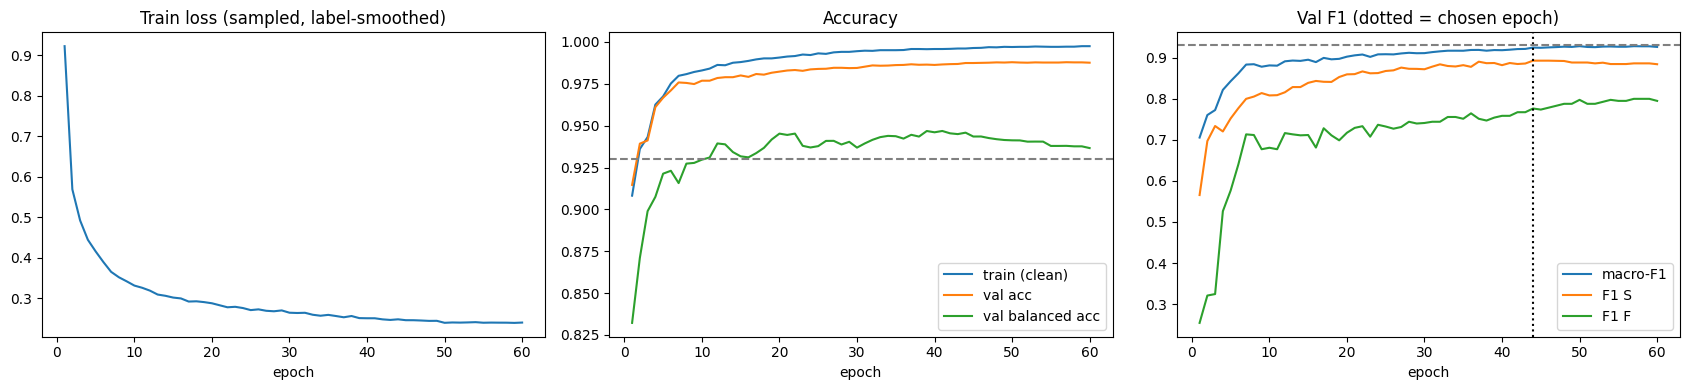

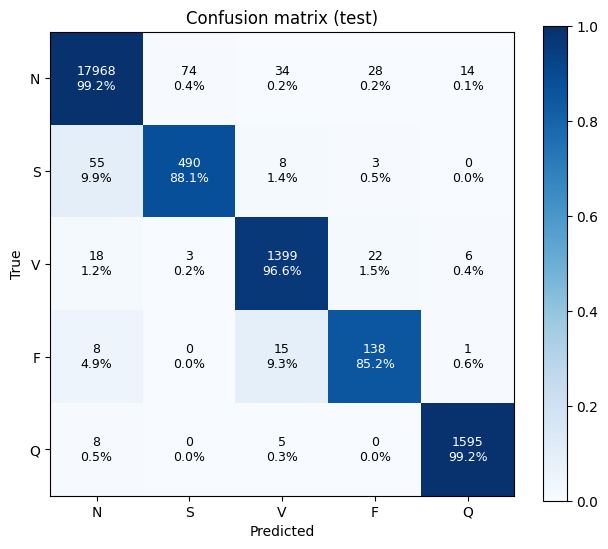

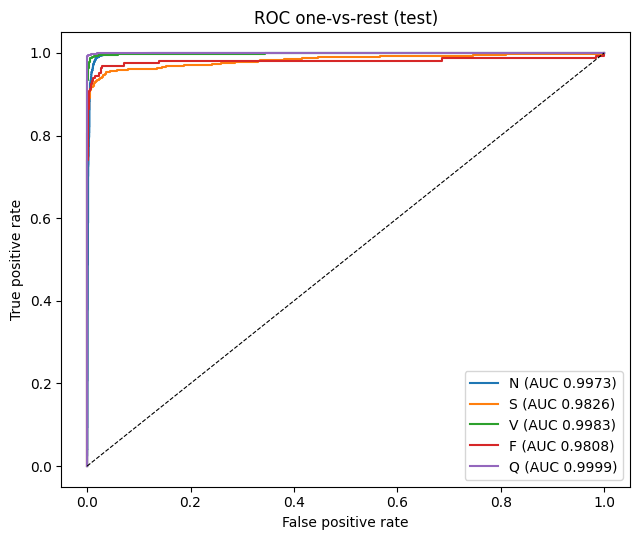

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ep = range(1, len(hist["val_acc"]) + 1)
ax[0].plot(ep, hist["train_loss"]); ax[0].set_title("Train loss (sampled, label-smoothed)"); ax[0].set_xlabel("epoch")
ax[1].plot(ep, hist["train_acc_clean"], label="train (clean)"); ax[1].plot(ep, hist["val_acc"], label="val acc")
ax[1].plot(ep, hist["val_bal"], label="val balanced acc"); ax[1].axhline(TARGET, ls="--", c="gray")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
ax[2].plot(ep, hist["val_f1"], label="macro-F1"); ax[2].plot(ep, hist["val_f1_S"], label="F1 S"); ax[2].plot(ep, hist["val_f1_F"], label="F1 F")
ax[2].axvline(best_epoch, ls=":", c="k"); ax[2].axhline(TARGET, ls="--", c="gray")
ax[2].set_title("Val F1 (dotted = chosen epoch)"); ax[2].set_xlabel("epoch"); ax[2].legend()
plt.tight_layout(); plt.savefig("/kaggle/working/training_curves.png", dpi=150); plt.show()

cm = confusion_matrix(y_test, test_pred); cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, f"{cm[i,j]}\n{cmn[i,j]*100:.1f}%", ha="center", va="center",
                color="white" if cmn[i, j] > 0.5 else "black", fontsize=9)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(SHORT); ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(SHORT)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Confusion matrix (test)")
plt.colorbar(im); plt.tight_layout(); plt.savefig("/kaggle/working/confusion_matrix.png", dpi=150); plt.show()

Y = label_binarize(y_test, classes=list(range(NUM_CLASSES)))
plt.figure(figsize=(6.5, 5.5))
for c in range(NUM_CLASSES):
    fpr, tpr, _ = roc_curve(Y[:, c], test_prob[:, c])
    plt.plot(fpr, tpr, label=f"{SHORT[c]} (AUC {auc(fpr, tpr):.4f})")
plt.plot([0, 1], [0, 1], "k--", lw=0.8); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC one-vs-rest (test)"); plt.legend(); plt.tight_layout()
plt.savefig("/kaggle/working/roc_curves.png", dpi=150); plt.show()

## 9. Save the model + the unchanged inference module
`ecg_inference.py` below is **byte-for-byte the same** as the one already on Hugging Face. Only `ecg_convnext_atto.pth` changes.

In [11]:
torch.save({
    "state_dict": {k: v.detach().cpu() for k, v in final.state_dict().items()},
    "classes": CLASSES,
    "temperature": TEMP,
    "config": {"model_name": CFG["model_name"], "img_size": CFG["img_size"], "spec_cfg": SPEC_CFG},
}, "/kaggle/working/ecg_convnext_atto.pth")

INFER_SRC = r"""
# ecg_inference.py : standalone inference for the ConvNeXt-Atto ECG beat classifier
# Input : beats of 187 samples (MIT-BIH style, 125 Hz, one heartbeat, amplitude scaled to 0-1)
# Output: calibrated probabilities for [N, S, V, F, Q] and an abnormal-risk score (1 - P(N))
import numpy as np, torch, torch.nn.functional as F, timm

class ECGClassifier:
    def __init__(self, path="ecg_convnext_atto.pth", device=None):
        self.device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
        ck = torch.load(path, map_location="cpu")
        self.classes, self.T = ck["classes"], ck["temperature"]
        self.size, self.spec = ck["config"]["img_size"], ck["config"]["spec_cfg"]
        self.model = timm.create_model(ck["config"]["model_name"], pretrained=False, num_classes=len(self.classes))
        self.model.load_state_dict(ck["state_dict"])
        self.model.to(self.device).eval()
        self.win = {n: torch.hann_window(n, device=self.device) for n, _ in self.spec}

    def _to_image(self, x):
        x = x - x.mean(dim=1, keepdim=True)
        chans = []
        for n_fft, hop in self.spec:
            S = torch.stft(x, n_fft=n_fft, hop_length=hop, win_length=n_fft, window=self.win[n_fft],
                           center=True, return_complex=True).abs()
            S = torch.log1p(20.0 * S).unsqueeze(1)
            chans.append(F.interpolate(S, size=(self.size, self.size), mode="bilinear", align_corners=False))
        img = torch.cat(chans, 1)
        return (img - img.mean(dim=(2, 3), keepdim=True)) / (img.std(dim=(2, 3), keepdim=True) + 1e-5)

    @torch.no_grad()
    def predict_proba(self, beats):
        x = torch.as_tensor(np.asarray(beats, dtype=np.float32), device=self.device)
        if x.ndim == 1:
            x = x[None]
        out = []
        for i in range(0, len(x), 256):
            logits = self.model(self._to_image(x[i:i + 256]))
            out.append(F.softmax(logits / self.T, dim=1).cpu().numpy())
        return np.concatenate(out)

    def risk_score(self, beats):
        return 1.0 - self.predict_proba(beats)[:, 0]
"""
with open("/kaggle/working/ecg_inference.py", "w") as f:
    f.write(INFER_SRC.strip() + "\n")

# sanity check: the standalone module must reproduce the notebook's test predictions exactly
sys.path.insert(0, "/kaggle/working")
from ecg_inference import ECGClassifier
clf = ECGClassifier("/kaggle/working/ecg_convnext_atto.pth")
chk = clf.predict_proba(X_test[:3000]).argmax(1)
print("standalone module matches notebook predictions:", float((chk == test_pred[:3000]).mean()))
print("example risk scores:", np.round(clf.risk_score(X_test[:5]), 4), "| true labels:", y_test[:5])

json.dump({"test": {k: float(v) for k, v in M.items()}, "test_f1_per_class": dict(zip(SHORT, map(float, f1_cls))),
           "temperature": TEMP, "class_bias": [float(b) for b in bias], "best_epoch": best_epoch, "epochs_planned": EPOCHS,
           "train_minutes": elapsed / 60}, open("/kaggle/working/results_v2.json", "w"), indent=2)

standalone module matches notebook predictions: 1.0
example risk scores: [0.0063 0.0068 0.006  0.0061 0.0063] | true labels: [0 0 0 0 0]


In [12]:
import zipfile
from IPython.display import FileLink, display

files = ["ecg_convnext_atto.pth", "ecg_inference.py", "results_v2.json",
         "training_curves.png", "confusion_matrix.png", "roc_curves.png"]
zip_path = "/kaggle/working/ecg_model_bundle.zip"
with zipfile.ZipFile(zip_path, "w") as z:
    for fn in files:
        p = f"/kaggle/working/{fn}"
        if os.path.exists(p):
            z.write(p, fn); print("Added:", fn)
        else:
            print("Not found:", fn)
if os.path.exists(CFG["ckpt"]):
    os.remove(CFG["ckpt"])                 # resume checkpoint is no longer needed
print("\nDownload your model:")
display(FileLink(zip_path))

Added: ecg_convnext_atto.pth
Added: ecg_inference.py
Added: results_v2.json
Added: training_curves.png
Added: confusion_matrix.png
Added: roc_curves.png

Download your model:


/kaggle/working/ecg_model_bundle.zip

## 10. Upload to Hugging Face
Replace only `ecg_convnext_atto.pth` in your HF repo with the new file. `ecg_inference.py` is identical, so the rest of your project keeps working.

```python
from ecg_inference import ECGClassifier
clf = ECGClassifier("ecg_convnext_atto.pth")
probs = clf.predict_proba(beat_187_samples)    # (N, 5): [N, S, V, F, Q]
ecg_risk = clf.risk_score(beat_187_samples)    # 1 - P(Normal)
```

**Notes for the report**
- The official MIT-BIH split here is beat-level, not patient-level, so scores are optimistic compared with unseen patients. Say so in the write-up.
- Class bias and temperature were fitted on validation only; the test set was used once, at the end.
- If the session disconnects mid-run, just re-run the notebook: the training cell resumes from `/kaggle/working/ckpt_last.pt`.